# Session 4: Convolutional Neural Networks and Filters

This notebook contains structured tasks based on Session 4 materials.

**Instructions:**
- Do NOT use a separate `.py` file. Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- For Visulaization, please use `%matplotlib inline`
- Submit your completed notebook by uploading it to your forked repository.

### ***DO NOT UPLOAD THE DATASET TO GITHUB as it's too large***
<hr>

## Task 1: Convolutional Filters on an Image
Apply several 2D filters (Sobel X, Sobel Y, Laplacian, and Sharpen) to an image and visualize the results side by side.

**Hint:**
- Use OpenCV (`cv2.filter2D`) or NumPy to apply kernels.
- Define common kernels (Sobel, Laplacian, Sharpen).
- Use `matplotlib.pyplot` to plot the original and filtered images.

In [5]:
import sys
print(sys.executable)

c:\Users\Prof. Ahmed ElShafee\anaconda3\python.exe


In [6]:
%pip install torch torchvision

   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.5/124.1 MB 1.3 MB/s eta 0:01:39
   ---------------------------------------- 1.3/124.1 MB 2.1 MB/s eta 0:00:58
    --------------------------------------- 1.8/124.1 MB 2.2 MB/s eta 0:00:56
    --------------------------------------- 2.1/124.1 MB 2.0 MB/s eta 0:01:01
    --------------------------------------- 2.6/124.1 MB 2.1 MB/s eta 0:01:00
   - -------------------------------------- 3.1/124.1 MB 2.1 MB/s eta 0:00:58
   - -------------------------------------- 3.7/124.1 MB 2.2 MB/s eta 0:00:55
   - -------------------------------------- 4.2/124.1 MB 2.2 MB/s eta 0:00:54
   - -------------------------------------- 4.5/124.1 MB 2.2 MB/s eta 0:00:55
   - -------------------------------------- 5.0/124.1 MB 2.1 MB/s eta 0:00:57
   - -------------------------------------- 5.2/124.1 MB 2.1 MB/s eta 0:00:57


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


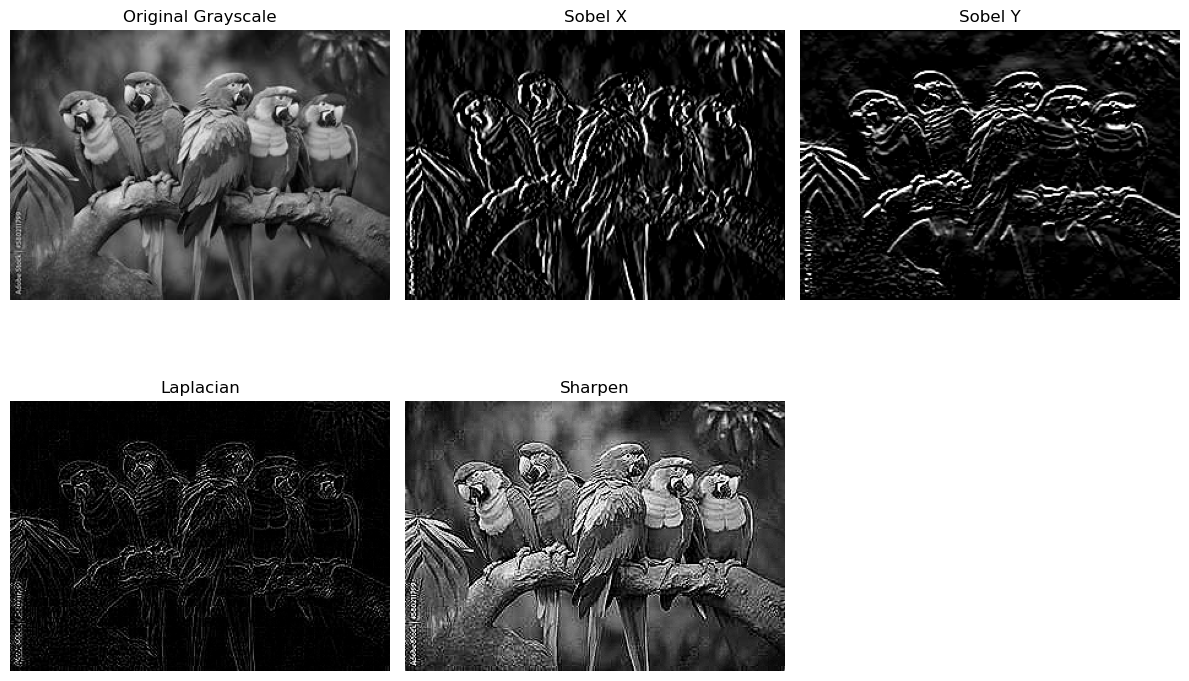

In [4]:
%matplotlib inline
#makes sure that the plots are displayed in the notebook

import cv2
import numpy as np
import matplotlib.pyplot as plt

img= cv2.imread("parrot.png")
gray= cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) #convert to grayscale


sobel_x= np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
],dtype=np.float32) 
#Sobel X is based on left-to-right intensity changes but the resulting edges are vertical.


sobel_y= np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
],dtype=np.float32) #sobel y highlights the changes in intensity in the vertical direction which corresponds to horizontal edges in the image.


laplacian= np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
],dtype=np.float32) #lapacian kernel is used to detect edges in all directions. 
#(It can be useful also for more than edge detection, like image sharpening and noise reduction.)

# Sharpening kernel - makes edges/details clearer
sharpen= np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
],dtype=np.float32) #from its name, it is used to sharpen the image. It enhances the edges and details in the image.

sobel_x_res= cv2.filter2D(gray, -1, sobel_x)
sobel_y_res= cv2.filter2D(gray, -1, sobel_y)
laplacian_res= cv2.filter2D(gray, -1, laplacian)
sharpen_res= cv2.filter2D(gray, -1, sharpen)

# TODO: Plot the original and filtered images
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(sobel_x_res, cmap="gray")
plt.title("Sobel X")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sobel_y_res, cmap="gray")
plt.title("Sobel Y")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(laplacian_res, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(sharpen_res, cmap="gray")
plt.title("Sharpen")
plt.axis("off")

plt.tight_layout()
plt.show()
#my obseravation is that sobel X and sobel Y highlight the edges in different directions (I can see the vertical edges in Sobel X
#and horizontal edges in Sobel Y),
#the Laplacian kernel detects edges in all directions.
#The sharpening kernel enhances the details and edges in the image, making it appear clearer.

## Task 2: Build a Simple CNN on FashionMNIST
Construct and train a small Convolutional Neural Network (CNN) on the FashionMNIST dataset.

**Hint:**
- Use `torchvision.datasets.FashionMNIST` for loading data.
- Define a small CNN with `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.Linear`.
- Train for a few epochs using an optimizer (e.g., Adam) and loss function (e.g., CrossEntropyLoss).
- Print training accuracy after each epoch.

In [14]:
import torch 
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
#Convert images to tensors and normalize them
transform= transforms.Compose([transforms.ToTensor(),transforms.Normalize((0.5,), (0.5,))])
#converted images to tensors and normalized them because the pixel values of the images are in the range [0, 1] 
#and we want to scale them to the range [-1, 1] for better training of the neural network. 

train_dataset= torchvision.datasets.FashionMNIST(root="./data",train=True,download=True,transform=transform) #download the FashionMNIST training dataset and applying transformations to the images. 
#the FashionMIINST dataset contains many training samples of different fashion items 

test_dataset= torchvision.datasets.FashionMNIST(root="./data",train=False,download=True,transform=transform)
#download the FashionMNIST test dataset and applying transformations to the images.


train_loader= torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
) #data loaders is used to load both training and testing datasets in batch size=64 and shuffle the training dataset
#shuffling the dataset helps the model to learn better and ovoid overfitting 

test_loader= torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
) #we mark the shuffle as false for the test dataset as there is no need to shuffle the test dataset since we are only evaluating the model's performance on it.

print("Training samples:", len(train_dataset)) 
print("Testing samples:", len(test_dataset))
#TODO: Define a simple CNN
class SimpleCNN(nn.Module):
    
    def __init__(self):
        super(SimpleCNN, self).__init__()
        
        #One convolutional layer
        self.conv= nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        ) 
        
        #Max pooling
        self.pool= nn.MaxPool2d(kernel_size=2, stride=2) 
        self.fc= nn.Linear(16 * 14 * 14, 10)

    def forward(self, x):
        
        #convolution+reLU+max Pooling
        x= self.conv(x)
        x= torch.relu(x)
        x= self.pool(x)
        
        x= x.view(x.size(0), -1) #flattening the output of the convolutional layer to feed it into the fully connected layer.
        
        x= self.fc(x) #this is the full connected layer that takes the flattened output and produces the final output of the network.
        
        return x


model= SimpleCNN()
print(model)

criterion= nn.CrossEntropyLoss() 
optimizer= optim.Adam(
    model.parameters(),
    lr=0.001
)
#fashionMINST is a classification problem bec it contains 10 classes of fashion items and the model is trained to classify 
#the input images. The cross-entropy loss measures the difference between the predicted class probabilities and the true class labels.

num_epochs = 3

for epoch in range(num_epochs):
    
    model.train()
    
    correct= 0
    total= 0
    
    for images, labels in train_loader:
        
        optimizer.zero_grad()
      
        outputs = model(images)
        
        loss = criterion(outputs, labels)
     
        loss.backward()
        
        optimizer.step()
        
        _, predicted= torch.max(outputs, 1)
        
        total+= labels.size(0)
        correct+= (predicted == labels).sum().item()
    #predicted labels are compared with the true labels to calculate the number of correct predictions.
    
    accuracy= 100*correct/total
    
    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {loss.item():.4f}, "
        f"Training Accuracy: {accuracy:.2f}%"
    )
    


Training samples: 60000
Testing samples: 10000
SimpleCNN(
  (conv): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=3136, out_features=10, bias=True)
)
Epoch [1/3], Loss: 0.4834, Training Accuracy: 84.27%
Epoch [2/3], Loss: 0.3952, Training Accuracy: 88.73%
Epoch [3/3], Loss: 0.1465, Training Accuracy: 89.93%


NOTE: The training accuracy is getting better with each epoch, which is a good indication that the CNN is learning patterns from the FashionMNIST images and improving its predictions. 

## Task 3: Visualize Feature Maps
Visualize feature maps produced by the first convolutional layer of your CNN.

**Hint:**
- Take a single image from the test set.
- Pass it through the first convolutional layer (`net.conv1`).
- Convert the output to NumPy and plot several channels as images.

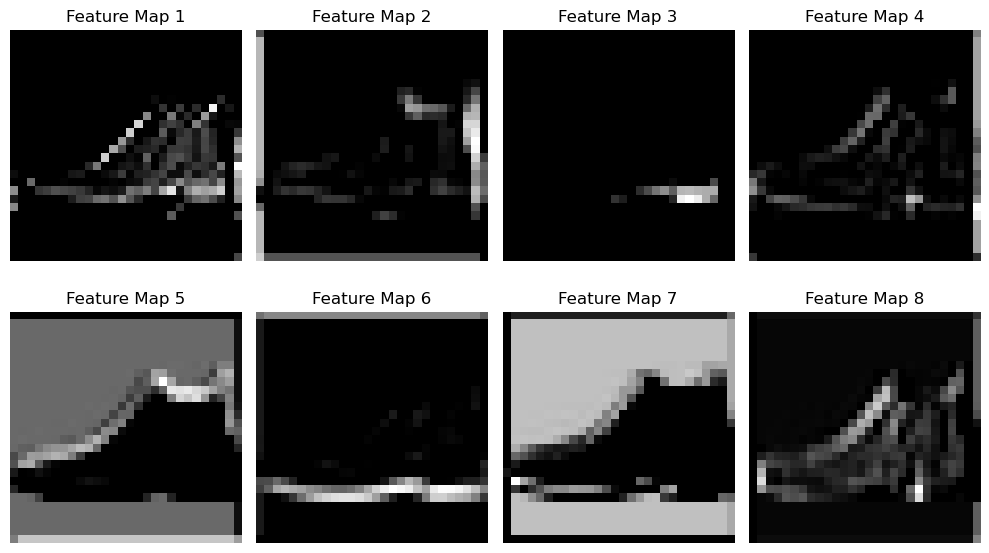

In [15]:
%matplotlib inline

image,label= test_dataset[0]

image= image.unsqueeze(0) 

# TODO: Forward pass through the first convolutional layer
model.eval()

with torch.no_grad():
    feature_maps= model.conv(image)

feature_maps= torch.relu(feature_maps)

feature_maps=feature_maps.squeeze(0).cpu().numpy()

plt.figure(figsize=(10, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(feature_maps[i], cmap="gray")
    plt.title(f"Feature Map {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Task 4: Haar Cascade Face Detection

Apply Haar Cascade classifiers for basic object detection (faces).

**Hint:**
- Use `cv2.CascadeClassifier` with a pre-trained XML file (e.g., `haarcascade_frontalface_default.xml`).
- Convert the input image to grayscale before detection.
- Use `detectMultiScale` to get bounding boxes.
- Draw rectangles on detected faces with `cv2.rectangle`.
- Visualize with Matplotlib.


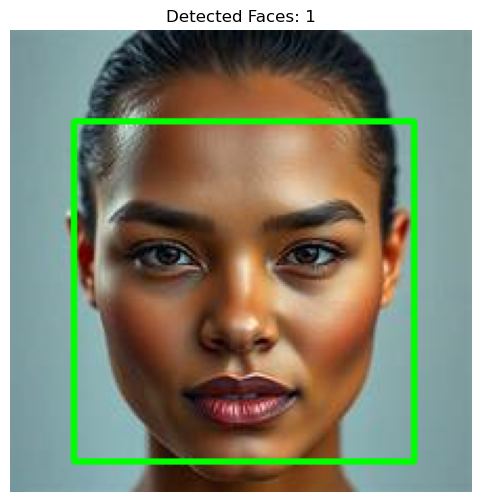

In [1]:
import cv2
import matplotlib.pyplot as plt
img=cv2.imread("face.png")

#Checking if the image was loaded successfully
if img is None: #if not loaded successfully, print an error message
    print("Image not found. Check the file path.")
else: 
    gray= cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) #we have to convert the image to grayscale because the Haar Cascade classifier works on single-channel images.

    face_cascade= cv2.CascadeClassifier(
        cv2.data.haarcascades+"haarcascade_frontalface_default.xml"
    )

    faces= face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    ) #detectMultiScale() searches for faces at different image scales.

    img_rgb= cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for (x, y, w, h) in faces:
        cv2.rectangle(
            img_rgb,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        ) 
        #Draws a green rectangle around detected faces. 
        #The rectangle is drawn on the RGB image, and the coordinates (x, y) represent the top-left corner of the rectangle, while (x + w, y + h) represent the bottom-right corner.
    plt.figure(figsize=(8, 6))
    plt.imshow(img_rgb)
    plt.title(f"Detected Faces: {len(faces)}")
    plt.axis("off")
    plt.show()

In [25]:
import cv2

print(cv2.__version__)
print(cv2.__file__)
print(hasattr(cv2, "CascadeClassifier"))

5.0.0
c:\Users\Prof. Ahmed ElShafee\anaconda3\Lib\site-packages\cv2\__init__.py
False


In [26]:
import cv2
import sys

print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("cv2 location:", getattr(cv2, "__file__", "Unknown"))
print("Python executable:", sys.executable)
print("CascadeClassifier exists:", hasattr(cv2, "CascadeClassifier"))
print("Available Cascade attributes:", [
    name for name in dir(cv2) if "Cascade" in name
])

OpenCV version: 5.0.0
cv2 location: c:\Users\Prof. Ahmed ElShafee\anaconda3\Lib\site-packages\cv2\__init__.py
Python executable: c:\Users\Prof. Ahmed ElShafee\anaconda3\python.exe
CascadeClassifier exists: False
Available Cascade attributes: []


In [27]:
%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93Note: you may need to restart the kernel to use updated packages.

Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93


You can safely remove it manually.


In [28]:
%pip install --no-cache-dir "opencv-python<5"



   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/41.2 MB ? eta -:--:--
    --------------------------------------- 0.8/41.2 MB 2.9 MB/s eta 0:00:14
    --------------------------------------- 0.8/41.2 MB 2.9 MB/s eta 0:00:14
   - -------------------------------------- 1.3/41.2 MB 1.4 MB/s eta 0:00:29
   - -------------------------------------- 1.6/41.2 MB 1.5 MB/s eta 0:00:27
   -- ------------------------------------- 2.1/41.2 MB 1.7 MB/s eta 0:00:24
   -- ------------------------------------- 2.9/41.2 MB 1.9 MB/s eta 0:00:20
   --- ------------------------------------ 3.7/41.2 MB 2.1 MB/s eta 0:00:18
   ---- ----------------------------------- 4.2/41.2 MB 2.2 MB/s eta 0:00:17
   ---- ----------------------------------- 5.0/41.2 MB 2.3 MB/s eta 0:00:16
   ----- ---------------------------------- 5.5/41.2 MB 2.3 MB/s eta 0:00:16
   ------ --------------------------------- 6.3/41.2 MB 2.4 MB/s eta 0:00:15
   ------ --